# REBCO-Gym Validation & Visualization Notebook

This notebook validates both Gymnasium environments and plots the underlying physics.

**Contents:**
1. Install & import
2. Physics validation — thermal runaway surfaces
3. Physics validation — quench antenna sensitivity
4. Physics validation — current redistribution mesh
5. ThermalRunawayEnv-v0 — episode rollouts & reward curves
6. CurrentRedistEnv-v0 — episode rollouts & mesh state plots
7. Comparing heuristic agents

In [2]:
# Cell 1: Install (run once)
# If you cloned the repo, install in editable mode:
# !pip install -e ./rebco_gym
#
# Or if the package is already installed, just import:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import gymnasium as gym
import rebco_gym

from rebco_gym.thermal import ThermalRunawayModel, Ic_T, lambda_brass, eta_from_geometry
from rebco_gym.quench_antenna import QuenchAntennaModel
from rebco_gym.current_redistribution import CurrentRedistributionMesh

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (8, 5)
print('All imports OK')

All imports OK


---
## 2. Physics: Thermal Runaway Surfaces

Reproduce the key result from Marchevsky & Prestemon (2024):
the runaway current I* as a function of base temperature T0 and cooling λ.

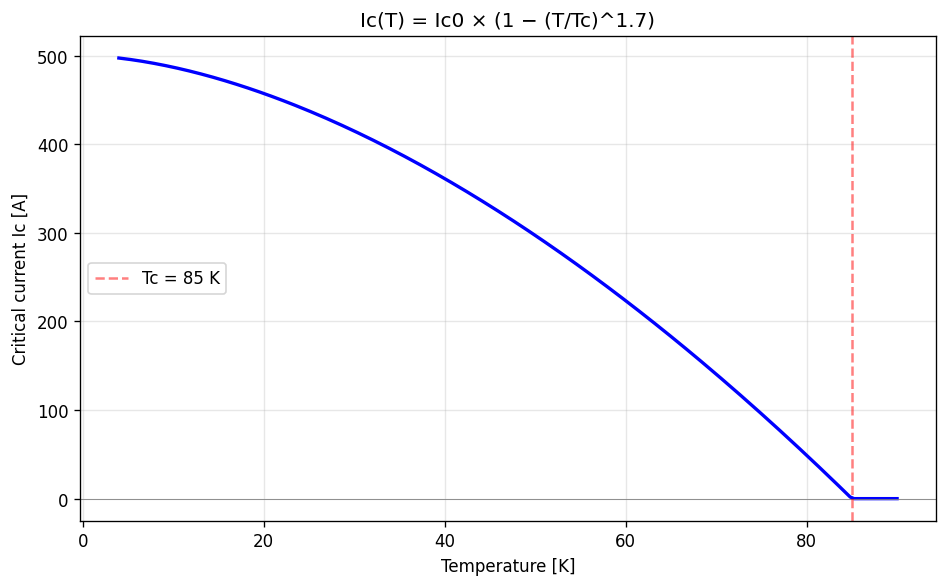

In [3]:
# 2a: Ic(T) curve
T_range = np.linspace(4, 90, 200)
Ic_vals = [Ic_T(T, Ic0=500, Tc=85) for T in T_range]

fig, ax = plt.subplots()
ax.plot(T_range, Ic_vals, 'b-', linewidth=2)
ax.set_xlabel('Temperature [K]')
ax.set_ylabel('Critical current Ic [A]')
ax.set_title('Ic(T) = Ic0 × (1 − (T/Tc)^1.7)')
ax.axhline(0, color='gray', linewidth=0.5)
ax.axvline(85, color='r', linestyle='--', alpha=0.5, label='Tc = 85 K')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

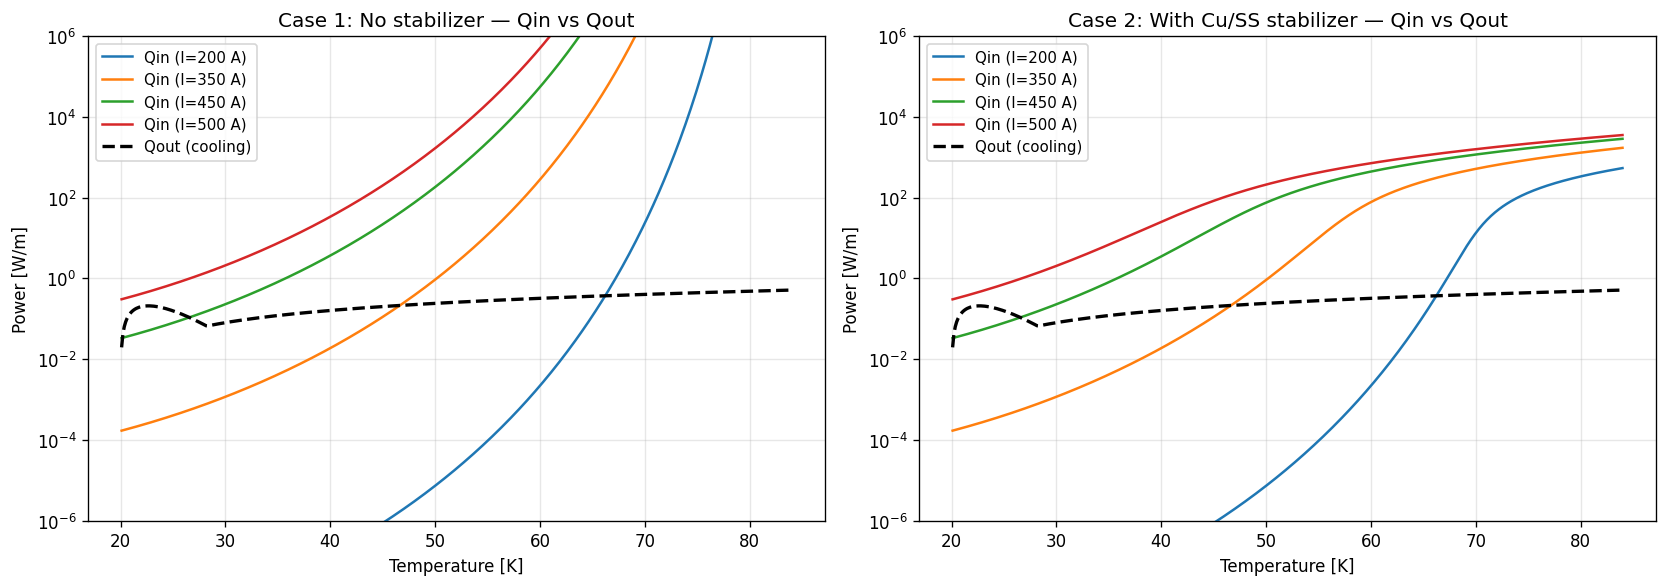

Where Qin crosses Qout from below = stable equilibrium T*
If Qin is always above Qout = thermal runaway (no equilibrium)


In [4]:
# 2b: Qin vs Qout balance — visualize thermal equilibrium
model = ThermalRunawayModel(Ic0=500, Tc=85, n_value=20)

T0 = 20.0
Ts = np.linspace(T0 + 0.1, 84, 500)
currents = [200, 350, 450, 500]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Case 1: no stabilizer
ax = axes[0]
for I in currents:
    qin = [model.Qin_case1(I, T) for T in Ts]
    ax.semilogy(Ts, qin, label=f'Qin (I={I} A)')
qout = [model.eta(T) * (T - T0) for T in Ts]
ax.semilogy(Ts, qout, 'k--', linewidth=2, label='Qout (cooling)')
ax.set_xlabel('Temperature [K]')
ax.set_ylabel('Power [W/m]')
ax.set_title('Case 1: No stabilizer — Qin vs Qout')
ax.set_ylim(1e-6, 1e6)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# Case 2: with stabilizer
ax = axes[1]
for I in currents:
    qin = [model.Qin_case2(I, T) for T in Ts]
    ax.semilogy(Ts, qin, label=f'Qin (I={I} A)')
ax.semilogy(Ts, qout, 'k--', linewidth=2, label='Qout (cooling)')
ax.set_xlabel('Temperature [K]')
ax.set_ylabel('Power [W/m]')
ax.set_title('Case 2: With Cu/SS stabilizer — Qin vs Qout')
ax.set_ylim(1e-6, 1e6)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print('Where Qin crosses Qout from below = stable equilibrium T*')
print('If Qin is always above Qout = thermal runaway (no equilibrium)')

Computing runaway surfaces (this takes ~30s)...
Done.


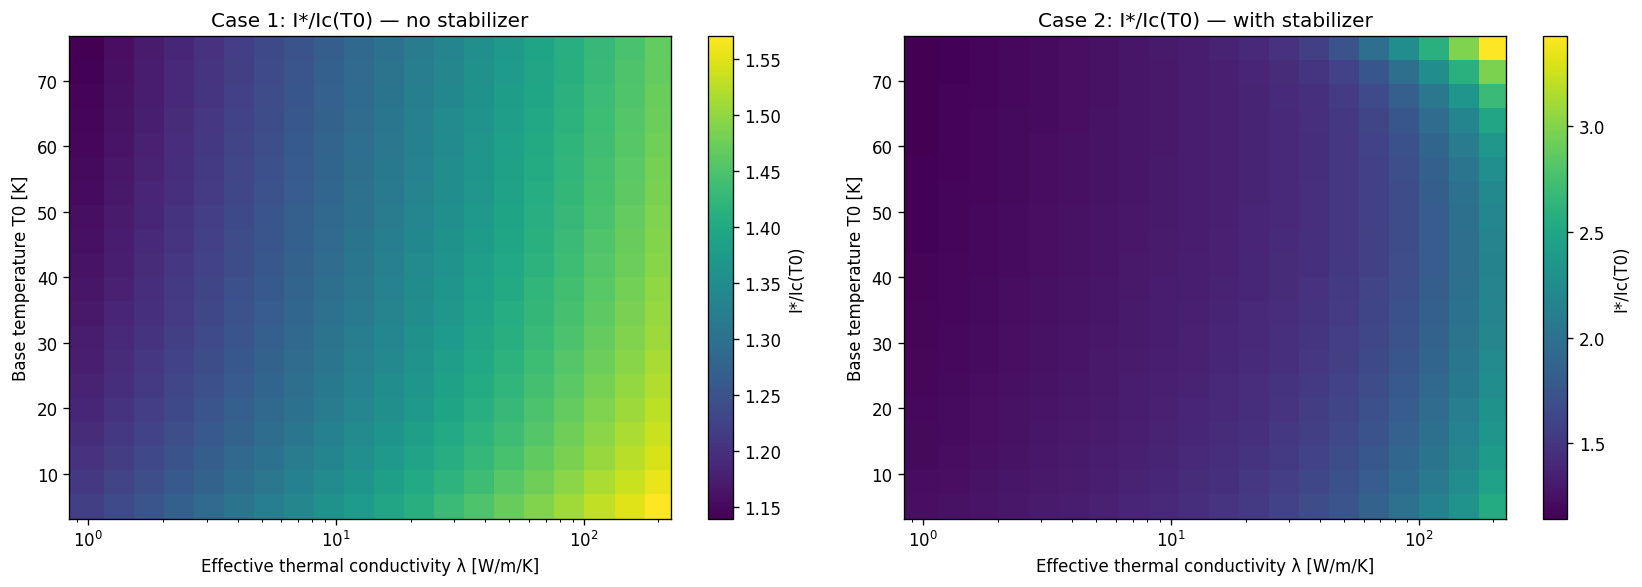

Higher I*/Ic = more margin before runaway. Stabilizer extends the safe region.


In [5]:
# 2c: Runaway current surface I*(T0, lambda)
# This reproduces the key figure from the paper

model = ThermalRunawayModel(Ic0=500, Tc=85, n_value=20)

T0_vals = np.linspace(5, 75, 20)
lambda_vals = np.logspace(np.log10(1), np.log10(200), 20)

Inorm_case1 = np.full((len(T0_vals), len(lambda_vals)), np.nan)
Inorm_case2 = np.full_like(Inorm_case1, np.nan)

print('Computing runaway surfaces (this takes ~30s)...')
for i, T0 in enumerate(T0_vals):
    for j, lam in enumerate(lambda_vals):
        eta = eta_from_geometry(lam, width=0.004, length=1.0, d_barrier=0.01)
        
        # Case 1
        I1, T1 = model.find_runaway_current(T0, eta, stabilized=False)
        if np.isfinite(I1):
            Inorm_case1[i, j] = I1 / Ic_T(T0, 500, 85)
        
        # Case 2
        I2, T2 = model.find_runaway_current(T0, eta, stabilized=True)
        if np.isfinite(I2):
            Inorm_case2[i, j] = I2 / Ic_T(T0, 500, 85)

print('Done.')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, title in zip(axes, 
    [Inorm_case1, Inorm_case2],
    ['Case 1: I*/Ic(T0) — no stabilizer', 'Case 2: I*/Ic(T0) — with stabilizer']):
    
    im = ax.pcolormesh(lambda_vals, T0_vals, data, shading='auto', cmap='viridis')
    ax.set_xscale('log')
    ax.set_xlabel('Effective thermal conductivity λ [W/m/K]')
    ax.set_ylabel('Base temperature T0 [K]')
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label='I*/Ic(T0)')

plt.tight_layout()
plt.show()
print('Higher I*/Ic = more margin before runaway. Stabilizer extends the safe region.')

In [ ]:
# 2d: Time-domain thermal trajectory at different operating points

model = ThermalRunawayModel(Ic0=500, Tc=85, n_value=20, C_eff=20.0)
dt = 0.002
t_max = 0.5

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, T0, title in zip(axes, [20.0, 50.0], ['T0 = 20 K', 'T0 = 50 K']):
    Ic0_val = Ic_T(T0, 500, 85)
    fractions = [0.5, 0.7, 0.85, 0.95, 1.05]
    
    for frac in fractions:
        I_op = frac * Ic0_val
        model.reset(T0=T0, I_op=I_op)
        
        ts, Ts = [0.0], [T0]
        t = 0.0
        while t < t_max:
            model.step(dt, stabilized=True)
            t += dt
            ts.append(t)
            Ts.append(model.T)
            if model.T > T0 + 50:
                break
        
        ax.plot(np.array(ts)*1000, Ts, label=f'I/Ic={frac:.2f} ({I_op:.0f}A)')
    
    ax.axhline(T0 + 12, color='r', linestyle='--', alpha=0.5, label='ΔT_crit = 12K')
    ax.set_xlabel('Time [ms]')
    ax.set_ylabel('Temperature [K]')
    ax.set_title(f'Thermal trajectory — {title}')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3. Physics: Quench Antenna Sensitivity Map

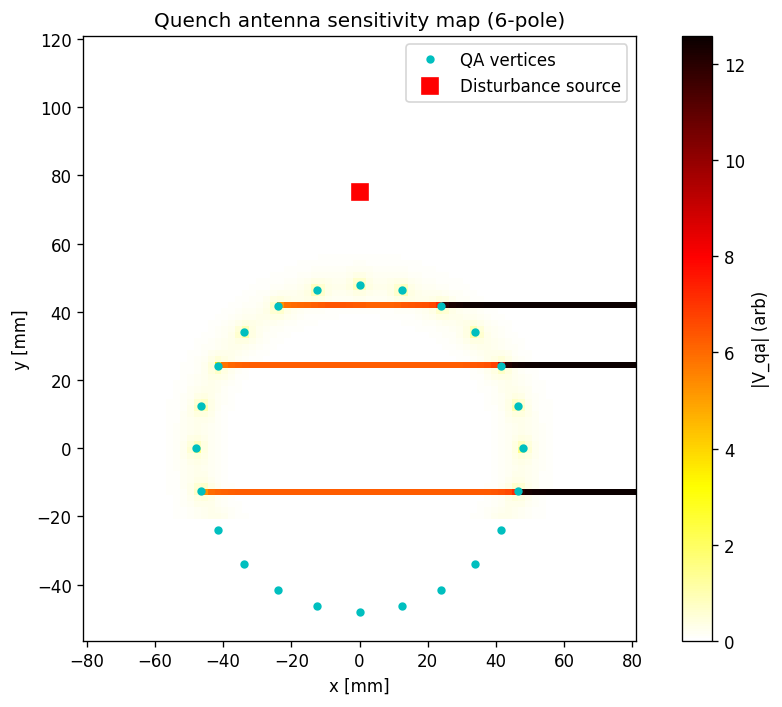

In [6]:
# 3a: QA voltage sensitivity as function of disturbance position

qa = QuenchAntennaModel(n_poles=6, antenna_radius=0.048)

X, Y, V = qa.sensitivity_map(
    x_range=(-0.08, 0.08),
    y_range=(-0.02, 0.12),
    n_points=80
)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.pcolormesh(X*1000, Y*1000, V, shading='auto', cmap='hot_r')
plt.colorbar(im, ax=ax, label='|V_qa| (arb)')

# Show antenna vertices
verts = qa._make_vertices()
ax.plot(np.real(verts)*1000, np.imag(verts)*1000, 'co', markersize=4, label='QA vertices')

# Show default disturbance location
ax.plot(np.real(qa.z_quench)*1000, np.imag(qa.z_quench)*1000, 
        'rs', markersize=10, label='Disturbance source')

ax.set_xlabel('x [mm]')
ax.set_ylabel('y [mm]')
ax.set_title('Quench antenna sensitivity map (6-pole)')
ax.set_aspect('equal')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 3b: Compare 6-pole vs 8-pole QA response

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, n_poles in zip(axes, [6, 8]):
    qa = QuenchAntennaModel(n_poles=n_poles, antenna_radius=0.048)
    X, Y, V = qa.sensitivity_map(n_points=60)
    im = ax.pcolormesh(X*1000, Y*1000, V, shading='auto', cmap='hot_r')
    plt.colorbar(im, ax=ax, label='|V_qa|')
    verts = qa._make_vertices()
    ax.plot(np.real(verts)*1000, np.imag(verts)*1000, 'co', markersize=3)
    ax.set_title(f'{n_poles}-pole QA sensitivity')
    ax.set_xlabel('x [mm]')
    ax.set_ylabel('y [mm]')
    ax.set_aspect('equal')

plt.tight_layout()
plt.show()

---
## 4. Physics: Current Redistribution Mesh

In [ ]:
# 4a: Steady-state current distribution across layers

mesh = CurrentRedistributionMesh(
    tape_width=4e-3, dx=0.5e-3, I_total=300, T_base=20, Ic0=500, Tc=85
)

print(f'Mesh: {mesh.nx} elements across {mesh.tape_width*1000:.1f} mm tape')
print(f'Layers: {mesh.layer_names}')
print()

# Show current density in each layer
fig, ax = plt.subplots(figsize=(10, 5))
x_mm = np.linspace(0, mesh.tape_width*1000, mesh.nx)

for iy, layer in enumerate(mesh.layer_names):
    J = mesh.J_field[iy, :]
    if np.max(np.abs(J)) > 1e3:  # skip layers with negligible current
        ax.semilogy(x_mm, np.abs(J), 'o-', label=layer, markersize=4)

ax.set_xlabel('Position across tape width [mm]')
ax.set_ylabel('|J| [A/m²]')
ax.set_title('Current density distribution by layer (T=20K, I=300A)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# REBCO fraction
frac = mesh.get_rebco_current_fraction()
print(f'REBCO carries {frac[0]*100:.1f}% of current (uniform across width)')

In [ ]:
# 4b: Time evolution with a hotspot — watch current redistribute

mesh = CurrentRedistributionMesh(
    tape_width=4e-3, dx=0.5e-3, I_total=400, T_base=30, Ic0=500, Tc=85
)

dt = 0.001
n_steps = 300
hotspot_step = 50  # inject hotspot at this step

# Recording arrays
times = []
T_history = []  # max T per step
T_profile_history = []  # full profile snapshots
Ic_history = []
frac_history = []

for step in range(n_steps):
    if step == hotspot_step:
        # Inject +5K at column 3 (center-ish)
        mesh.T_field[:, 3] += 5.0
        print(f'Step {step}: Injected +5K hotspot at column 3')
    
    mesh.step(dt)
    
    times.append(step * dt * 1000)  # ms
    T_history.append(mesh.max_temperature())
    T_profile_history.append(mesh.T_field[0, :].copy())  # column temps
    Ic_history.append(mesh.get_Ic_distribution().copy())
    frac_history.append(mesh.get_rebco_current_fraction().copy())

times = np.array(times)
T_history = np.array(T_history)
T_profiles = np.array(T_profile_history)
Ic_profiles = np.array(Ic_history)
frac_profiles = np.array(frac_history)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Max temperature
ax = axes[0, 0]
ax.plot(times, T_history, 'b-')
ax.axhline(30 + 12, color='r', linestyle='--', label='ΔT_crit')
ax.axvline(hotspot_step * dt * 1000, color='orange', linestyle=':', label='Hotspot injected')
ax.set_xlabel('Time [ms]')
ax.set_ylabel('Max temperature [K]')
ax.set_title('Peak temperature evolution')
ax.legend()
ax.grid(True, alpha=0.3)

# Temperature profile waterfall
ax = axes[0, 1]
x_mm = np.linspace(0, mesh.tape_width*1000, mesh.nx)
for idx in [0, hotspot_step, hotspot_step+10, hotspot_step+50, n_steps-1]:
    if idx < len(T_profiles):
        ax.plot(x_mm, T_profiles[idx], 'o-', markersize=4, 
                label=f't={times[idx]:.1f}ms')
ax.set_xlabel('Position [mm]')
ax.set_ylabel('Temperature [K]')
ax.set_title('Temperature profile snapshots')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Ic distribution
ax = axes[1, 0]
for idx in [0, hotspot_step+5, hotspot_step+20, hotspot_step+50]:
    if idx < len(Ic_profiles):
        ax.plot(x_mm, Ic_profiles[idx], 'o-', markersize=4,
                label=f't={times[idx]:.1f}ms')
ax.set_xlabel('Position [mm]')
ax.set_ylabel('Ic [A]')
ax.set_title('Local critical current Ic(x) after hotspot')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# REBCO current fraction
ax = axes[1, 1]
im = ax.pcolormesh(x_mm, times, frac_profiles, shading='auto', cmap='RdYlGn')
plt.colorbar(im, ax=ax, label='REBCO current fraction')
ax.axhline(hotspot_step * dt * 1000, color='white', linestyle='--', linewidth=0.8)
ax.set_xlabel('Position [mm]')
ax.set_ylabel('Time [ms]')
ax.set_title('REBCO current fraction (space-time)')

plt.tight_layout()
plt.show()

In [ ]:
# 4c: E-field distribution (what COMSOL would show)

mesh = CurrentRedistributionMesh(
    tape_width=4e-3, dx=0.5e-3, I_total=400, T_base=30, Ic0=500, Tc=85
)

# Run to steady state then add hotspot
for _ in range(20):
    mesh.step(0.001)
mesh.T_field[:, 4] += 8.0
for _ in range(5):
    mesh.step(0.001)

E = mesh.get_E_field()
x_mm = np.linspace(0, mesh.tape_width*1000, mesh.nx)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# E-field heatmap
ax = axes[0]
im = ax.imshow(np.log10(np.abs(E) + 1e-20), aspect='auto', cmap='inferno',
               extent=[0, mesh.tape_width*1000, len(mesh.layer_names)-0.5, -0.5])
ax.set_yticks(range(len(mesh.layer_names)))
ax.set_yticklabels(mesh.layer_names, fontsize=8)
ax.set_xlabel('Position [mm]')
ax.set_title('log10(|E|) [V/m]')
plt.colorbar(im, ax=ax)

# Temperature
ax = axes[1]
im = ax.imshow(mesh.T_field, aspect='auto', cmap='hot',
               extent=[0, mesh.tape_width*1000, len(mesh.layer_names)-0.5, -0.5])
ax.set_yticks(range(len(mesh.layer_names)))
ax.set_yticklabels(mesh.layer_names, fontsize=8)
ax.set_xlabel('Position [mm]')
ax.set_title('Temperature [K]')
plt.colorbar(im, ax=ax)

# Jc vs J at REBCO layer
ax = axes[2]
rebco_idx = mesh.layer_names.index('rebco')
Jc = mesh.get_Jc_field()
J_rebco = np.abs(mesh.J_field[rebco_idx, :])
ax.bar(x_mm - 0.1, Jc/1e9, width=0.2, label='Jc', alpha=0.7, color='green')
ax.bar(x_mm + 0.1, J_rebco/1e9, width=0.2, label='J (actual)', alpha=0.7, color='red')
ax.set_xlabel('Position [mm]')
ax.set_ylabel('Current density [GA/m²]')
ax.set_title('Jc vs J at REBCO layer')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 5. ThermalRunawayEnv-v0 — Episode Rollouts

In [ ]:
# 5a: Single episode trace with detailed state plotting

env = gym.make('ThermalRunawayEnv-v0', disturbance_prob=0.06, max_steps=400)
obs, info = env.reset(seed=42)

# Record episode
history = {'T': [], 'T0': [], 'I_op': [], 'Ic': [], 'dTdt': [], 
           'V_qa': [], 'margin': [], 'action': [], 'reward': []}

done = False
total_reward = 0

while not done:
    T, T0, I_op, Ic_T_val, dTdt, V_qa, margin = obs
    
    # Heuristic agent
    action = 1 if (margin > 0.85 or dTdt > 1.0 or V_qa > 0.5) else 0
    
    for key, val in zip(history.keys(), [T, T0, I_op, Ic_T_val, dTdt, V_qa, margin, action, 0]):
        history[key].append(val)
    
    obs, reward, terminated, truncated, info = env.step(action)
    history['reward'][-1] = reward
    total_reward += reward
    done = terminated or truncated

env.close()

# Convert to arrays
for k in history:
    history[k] = np.array(history[k])
steps = np.arange(len(history['T']))

print(f'Episode finished: {len(steps)} steps, total reward = {total_reward:.1f}')
print(f'Final state: T={history["T"][-1]:.1f}K, ΔT={history["T"][-1]-history["T0"][-1]:.1f}K')

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

# Temperature
ax = axes[0, 0]
ax.plot(steps, history['T'], 'b-', label='T')
ax.plot(steps, history['T0'], 'g--', label='T0 (coolant)')
ax.plot(steps, history['T0'] + 12, 'r--', alpha=0.5, label='T0 + ΔT_crit')
ax.set_ylabel('Temperature [K]')
ax.set_title('Temperature evolution')
ax.legend()
ax.grid(True, alpha=0.3)

# Current vs Ic
ax = axes[0, 1]
ax.plot(steps, history['I_op'], 'b-', label='I_op')
ax.plot(steps, history['Ic'], 'r-', label='Ic(T)')
ax.fill_between(steps, history['I_op'], history['Ic'], 
                alpha=0.2, color='green', label='Margin')
ax.set_ylabel('Current [A]')
ax.set_title('Operating current vs critical current')
ax.legend()
ax.grid(True, alpha=0.3)

# dT/dt
ax = axes[1, 0]
ax.plot(steps, history['dTdt'], 'orange')
ax.axhline(0, color='gray', linewidth=0.5)
ax.set_ylabel('dT/dt [K/s]')
ax.set_title('Temperature rate of change')
ax.grid(True, alpha=0.3)

# QA voltage
ax = axes[1, 1]
ax.plot(steps, history['V_qa'], 'purple')
ax.set_ylabel('V_qa [arb]')
ax.set_title('Quench antenna voltage signal')
ax.grid(True, alpha=0.3)

# Actions
ax = axes[2, 0]
ax.step(steps, history['action'], 'k-', where='post')
ax.set_yticks([0, 1])
ax.set_yticklabels(['HOLD', 'RAMP DOWN'])
ax.set_ylabel('Action')
ax.set_xlabel('Step')
ax.set_title('Agent actions')
ax.grid(True, alpha=0.3)

# Cumulative reward
ax = axes[2, 1]
ax.plot(steps, np.cumsum(history['reward']), 'g-')
ax.set_ylabel('Cumulative reward')
ax.set_xlabel('Step')
ax.set_title('Cumulative reward')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# 5b: Multi-episode statistics — compare agents

def run_episodes(env_kwargs, policy_fn, n_episodes=50, seed_offset=0):
    """Run n_episodes and collect stats."""
    env = gym.make('ThermalRunawayEnv-v0', **env_kwargs)
    results = []
    
    for ep in range(n_episodes):
        obs, info = env.reset(seed=ep + seed_offset)
        total_reward = 0
        done = False
        
        while not done:
            action = policy_fn(obs)
            obs, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            done = terminated or truncated
        
        quenched = info.get('dT', 0) >= 12.0
        results.append({
            'reward': total_reward,
            'steps': info['step'],
            'quenched': quenched,
            'final_T': info['T'],
            'safe_shutdown': terminated and not quenched,
        })
    
    env.close()
    return results

# Define policies
def never_ramp(obs):
    return 0  # always hold

def always_ramp(obs):
    return 1  # always ramp down

def conservative_agent(obs):
    T, T0, I_op, Ic, dTdt, V_qa, margin = obs
    return 1 if (margin > 0.8 or dTdt > 0.5) else 0

def aggressive_agent(obs):
    T, T0, I_op, Ic, dTdt, V_qa, margin = obs
    return 1 if (margin > 0.95 or dTdt > 5.0) else 0

def smart_agent(obs):
    T, T0, I_op, Ic, dTdt, V_qa, margin = obs
    return 1 if (margin > 0.85 or dTdt > 1.0 or V_qa > 0.3) else 0

env_kwargs = dict(disturbance_prob=0.06, max_steps=300)
n_ep = 100

print(f'Running {n_ep} episodes per agent...')
policies = {
    'Never ramp': never_ramp,
    'Always ramp': always_ramp,
    'Conservative': conservative_agent,
    'Aggressive': aggressive_agent,
    'Smart (margin+dTdt+QA)': smart_agent,
}

all_results = {}
for name, policy in policies.items():
    all_results[name] = run_episodes(env_kwargs, policy, n_episodes=n_ep)
    rewards = [r['reward'] for r in all_results[name]]
    quench_rate = sum(r['quenched'] for r in all_results[name]) / n_ep
    print(f'  {name:30s}: reward={np.mean(rewards):7.1f} ± {np.std(rewards):5.1f}, '
          f'quench_rate={quench_rate:.0%}')

print('Done.')

In [ ]:
# 5c: Plot agent comparison

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

names = list(all_results.keys())
colors = ['#E24B4A', '#888780', '#1D9E75', '#D85A30', '#378ADD']

# Reward distribution
ax = axes[0]
reward_data = [np.array([r['reward'] for r in all_results[n]]) for n in names]
bp = ax.boxplot(reward_data, labels=[n.split('(')[0].strip() for n in names], 
                patch_artist=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
ax.set_ylabel('Episode reward')
ax.set_title('Reward distribution by agent')
ax.tick_params(axis='x', rotation=30)
ax.grid(True, alpha=0.3)

# Quench rate
ax = axes[1]
quench_rates = [sum(r['quenched'] for r in all_results[n])/n_ep for n in names]
bars = ax.bar(range(len(names)), quench_rates, color=colors, alpha=0.7)
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.split('(')[0].strip() for n in names], rotation=30)
ax.set_ylabel('Quench rate')
ax.set_title('Quench rate by agent')
ax.set_ylim(0, 1)
for bar, rate in zip(bars, quench_rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{rate:.0%}', ha='center', fontsize=9)
ax.grid(True, alpha=0.3, axis='y')

# Episode length
ax = axes[2]
step_data = [np.array([r['steps'] for r in all_results[n]]) for n in names]
bp2 = ax.boxplot(step_data, labels=[n.split('(')[0].strip() for n in names],
                 patch_artist=True)
for patch, color in zip(bp2['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
ax.set_ylabel('Episode length (steps)')
ax.set_title('Episode length by agent')
ax.tick_params(axis='x', rotation=30)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 6. CurrentRedistEnv-v0 — Episode Rollouts

In [ ]:
# 6a: Single episode with mesh state visualization

env = gym.make('CurrentRedistEnv-v0', disturbance_prob=0.06, max_steps=500)
obs, info = env.reset(seed=77)
nx = env.unwrapped.nx
T0 = info['T0']

history = {'T_max': [], 'I_total': [], 'action': [], 'reward': [],
           'Ic_profiles': [], 'T_profiles': []}

done = False
total_reward = 0

while not done:
    T_max = obs[4*nx + 2]
    dT = T_max - T0
    frac = max(1.0 - (dT / 12.0), 0.1)
    action = np.array([frac], dtype=np.float32)
    
    history['T_max'].append(T_max)
    history['I_total'].append(obs[4*nx + 1])
    history['action'].append(frac)
    history['Ic_profiles'].append(obs[:nx].copy())
    history['T_profiles'].append(obs[3*nx:4*nx].copy())
    
    obs, reward, terminated, truncated, info = env.step(action)
    history['reward'].append(reward)
    total_reward += reward
    done = terminated or truncated

env.close()

for k in history:
    history[k] = np.array(history[k])
steps = np.arange(len(history['T_max']))

print(f'Episode: {len(steps)} steps, reward={total_reward:.1f}, T0={T0:.1f}K')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# T_max
ax = axes[0, 0]
ax.plot(steps, history['T_max'], 'b-')
ax.axhline(T0 + 12, color='r', linestyle='--', label='ΔT_crit')
ax.axhline(T0, color='g', linestyle='--', alpha=0.5, label='T0')
ax.set_ylabel('T_max [K]')
ax.set_title('Peak temperature')
ax.legend()
ax.grid(True, alpha=0.3)

# Current & action
ax = axes[0, 1]
ax.plot(steps, history['I_total'], 'b-', label='I_total')
ax2 = ax.twinx()
ax2.plot(steps, history['action'], 'orange', alpha=0.5, label='Action (fraction)')
ax.set_ylabel('Current [A]')
ax2.set_ylabel('Action fraction')
ax.set_title('Current and control action')
ax.legend(loc='upper left')
ax2.legend(loc='upper right')
ax.grid(True, alpha=0.3)

# Ic profile heatmap
ax = axes[1, 0]
x_mm = np.linspace(0, env.unwrapped.tape_width*1000, nx)
im = ax.pcolormesh(x_mm, steps, history['Ic_profiles'], shading='auto', cmap='viridis')
plt.colorbar(im, ax=ax, label='Ic [A]')
ax.set_xlabel('Position [mm]')
ax.set_ylabel('Step')
ax.set_title('Ic(x) distribution over time')

# Temperature profile heatmap
ax = axes[1, 1]
im = ax.pcolormesh(x_mm, steps, history['T_profiles'], shading='auto', cmap='hot')
plt.colorbar(im, ax=ax, label='T [K]')
ax.set_xlabel('Position [mm]')
ax.set_ylabel('Step')
ax.set_title('REBCO temperature profile over time')

plt.tight_layout()
plt.show()

In [ ]:
# 6b: Compare controller strategies for CurrentRedistEnv

def run_redist_episodes(policy_fn, n_episodes=30, seed_offset=0):
    env = gym.make('CurrentRedistEnv-v0', disturbance_prob=0.06, max_steps=500)
    results = []
    for ep in range(n_episodes):
        obs, info = env.reset(seed=ep + seed_offset)
        nx = env.unwrapped.nx
        total_reward = 0
        done = False
        while not done:
            action = policy_fn(obs, info, nx)
            obs, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            done = terminated or truncated
        results.append({
            'reward': total_reward,
            'steps': info['step'],
            'T_max': info['T_max'],
            'quenched': info['T_max'] >= info['T0'] + 12,
        })
    env.close()
    return results

def full_current(obs, info, nx):
    return np.array([1.0], dtype=np.float32)

def proportional_ctrl(obs, info, nx):
    T_max = obs[4*nx + 2]
    dT = T_max - info['T0']
    frac = max(1.0 - dT / 12.0, 0.1)
    return np.array([frac], dtype=np.float32)

def bang_bang_ctrl(obs, info, nx):
    T_max = obs[4*nx + 2]
    dT = T_max - info['T0']
    frac = 0.3 if dT > 6.0 else 1.0
    return np.array([frac], dtype=np.float32)

print('Running 30 episodes per controller...')
controllers = {
    'Full current (no protection)': full_current,
    'Proportional controller': proportional_ctrl,
    'Bang-bang (50% threshold)': bang_bang_ctrl,
}

ctrl_results = {}
for name, ctrl in controllers.items():
    ctrl_results[name] = run_redist_episodes(ctrl, n_episodes=30)
    rewards = [r['reward'] for r in ctrl_results[name]]
    qr = sum(r['quenched'] for r in ctrl_results[name]) / 30
    print(f'  {name:35s}: reward={np.mean(rewards):7.1f} ± {np.std(rewards):5.1f}, quench={qr:.0%}')

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
names = list(ctrl_results.keys())
colors = ['#E24B4A', '#1D9E75', '#378ADD']

ax = axes[0]
data = [np.array([r['reward'] for r in ctrl_results[n]]) for n in names]
bp = ax.boxplot(data, labels=[n.split('(')[0].strip() for n in names], patch_artist=True)
for patch, c in zip(bp['boxes'], colors):
    patch.set_facecolor(c); patch.set_alpha(0.5)
ax.set_ylabel('Episode reward')
ax.set_title('Controller reward comparison')
ax.tick_params(axis='x', rotation=20)
ax.grid(True, alpha=0.3)

ax = axes[1]
qr = [sum(r['quenched'] for r in ctrl_results[n])/30 for n in names]
bars = ax.bar(range(len(names)), qr, color=colors, alpha=0.7)
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.split('(')[0].strip() for n in names], rotation=20)
ax.set_ylabel('Quench rate')
ax.set_title('Quench rate by controller')
ax.set_ylim(0, 1)
for bar, rate in zip(bars, qr):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f'{rate:.0%}', ha='center')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

---
## 7. Observation Space Sanity Checks

Quick checks that observations stay bounded and physics are consistent.

In [ ]:
# 7a: Observation statistics over many steps

env = gym.make('ThermalRunawayEnv-v0', disturbance_prob=0.05, max_steps=200)
all_obs = []

for ep in range(20):
    obs, _ = env.reset(seed=ep)
    done = False
    while not done:
        all_obs.append(obs.copy())
        action = 1 if obs[6] > 0.9 else 0  # margin-based
        obs, _, term, trunc, _ = env.step(action)
        done = term or trunc

env.close()
all_obs = np.array(all_obs)

labels = ['T [K]', 'T0 [K]', 'I_op [A]', 'Ic(T) [A]', 'dT/dt [K/s]', 'V_qa', 'margin']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for i, (ax, label) in enumerate(zip(axes[:7], labels)):
    ax.hist(all_obs[:, i], bins=40, alpha=0.7, color='steelblue', edgecolor='white')
    ax.set_title(label)
    ax.set_ylabel('Count')
    stats = f'μ={np.mean(all_obs[:,i]):.1f}\nσ={np.std(all_obs[:,i]):.1f}'
    ax.text(0.95, 0.95, stats, transform=ax.transAxes, va='top', ha='right', fontsize=8,
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

axes[7].axis('off')
axes[7].text(0.5, 0.5, f'Total observations:\n{len(all_obs):,}\n\nAll values finite: '
             f'{np.all(np.isfinite(all_obs))}', transform=axes[7].transAxes,
             ha='center', va='center', fontsize=12)

plt.suptitle('ThermalRunawayEnv-v0: Observation space distribution (20 episodes)', y=1.02)
plt.tight_layout()
plt.show()

# Sanity checks
print('Sanity checks:')
print(f'  All temperatures > 0: {np.all(all_obs[:, 0] > 0)}')
print(f'  T >= T0 always: {np.all(all_obs[:, 0] >= all_obs[:, 1] - 0.01)}')
print(f'  Ic > 0 always: {np.all(all_obs[:, 3] > 0)}')
print(f'  margin >= 0: {np.all(all_obs[:, 6] >= 0)}')
print(f'  No NaN/Inf: {np.all(np.isfinite(all_obs))}')

---
## Next Steps

Once you're happy with the physics validation above, try:

```python
# Train with stable-baselines3
from stable_baselines3 import PPO

env = gym.make('ThermalRunawayEnv-v0', disturbance_prob=0.06)
model = PPO('MlpPolicy', env, verbose=1, n_steps=512)
model.learn(total_timesteps=100_000)
model.save('rebco_thermal_ppo')
```